In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from IPython.display import Markdown
import tabulate
import glob
import seaborn as sns

In [6]:
bikeshare_toronto_2024 = pd.read_csv(r"C:\Users\darre\OneDrive\Documents\STATS 780\Project\bikeshare-ridership-2024\bikeshare-ridership-2024.csv")

# concatenating csv files for 2025 since 2025 data was separated by month

# 1. Grab all Excel files in the target directory
file_path = "C:/Users/darre/OneDrive/Documents/STATS 780/Project/bikeshare-ridership-2025/*.csv"
all_files = glob.glob(file_path)

# 2. Read them all into a list of DataFrames using a list comprehension
df_list = [pd.read_csv(file, encoding='latin1') for file in all_files]

# 3. Concatenate the whole list at once (highly efficient)
bikeshare_toronto_2025 = pd.concat(df_list, ignore_index=True)

In [7]:
bikeshare_toronto_2026 = pd.read_csv(r"C:\Users\darre\OneDrive\Documents\STATS 780\Project\bikeshare-ridership-2026.csv")

In [8]:
union2024 = bikeshare_toronto_2024.loc[bikeshare_toronto_2024['Start_Station_Name'] == 'Union Station']
union2025 = bikeshare_toronto_2025.loc[bikeshare_toronto_2025['Start_Station_Name'] == 'Union Station']
union2026 = bikeshare_toronto_2026.loc[bikeshare_toronto_2026['Start_Station_Name'] == 'Union Station']

In [9]:
union2026

,Trip_Id,Trip_Duration,Start_Station_Id,Start_Time,Start_Station_Name,End_Station_Id,End_Time,End_Station_Name,Bike_Id,User_Type,Bike_Model
12,43682428,1762,7033,2026-01-01 00:14:45,Union Station,7259.0,2026-01-01 00:44:07,Lower Spadina Ave / Lake Shore Blvd W,2783,Casual,ICONIC
42,43682462,1642,7033,2026-01-01 00:33:46,Union Station,7199.0,2026-01-01 01:01:08,College St / Markham St,5490,Casual,ICONIC
257,43682797,1192,7033,2026-01-01 03:27:35,Union Station,7014.0,2026-01-01 03:47:27,Sherbourne St / Carlton St (Allan Gardens),2341,Member,ICONIC
490,43683101,467,7033,2026-01-01 10:02:03,Union Station,7253.0,2026-01-01 10:09:50,John St / Mercer St - SMART,10442,Member,ICONIC
537,43683150,347,7033,2026-01-01 10:44:08,Union Station,7757.0,2026-01-01 10:49:55,The Well,9407,Member,ICONIC
...,...,...,...,...,...,...,...,...,...,...,...
6828604,51511695,996,7033,2026-09-30 22:22:54,Union Station,7309.0,2026-09-30 22:39:30,Queen St E / Rhodes Ave,6794,Member,EFIT
6828607,51511698,547,7033,2026-09-30 22:23:00,Union Station,7693.0,2026-09-30 22:32:07,Mutual St / Shuter St,11159,Member,ICONIC
6829202,51512370,1188,7033,2026-09-30 22:50:39,Union Station,7133.0,2026-09-30 23:10:27,Summerhill Subway Station,3884,Member,ICONIC
6829875,51513213,642,7033,2026-09-30 23:32:11,Union Station,7534.0,2026-09-30 23:42:53,Walnut Ave / Queen St W,7928,Casual,EFIT


In [10]:
# Extract month, day of the week, and hour for when the trip started
for df in [union2024, union2025, union2026]:
    df["Start_Time"] = pd.to_datetime(df["Start_Time"])
    df["Start_Hour"] = df["Start_Time"].dt.hour
    df["Start_Day_of_Week"] = df["Start_Time"].dt.day_name()
    df["Month"] = df["Start_Time"].dt.month
    df["Year"] = df["Start_Time"].dt.year

In [11]:
union2024.head(1)

,Trip_Id,Trip_Duration,Start_Station_Id,Start_Time,Start_Station_Name,End_Station_Id,End_Time,End_Station_Name,Bike_Id,User_Type,Bike_Model,Start_Hour,Start_Day_of_Week,Month,Year
51,26682804,1234,7033,2024-01-01 00:30:46,Union Station,7100.0,2024-01-01 00:51:20,Dundas St E / Regent Park Blvd,8019,Member,EFIT G5,0,Monday,1,2024


In [12]:
union2025.head(1)

,Trip_Id,Trip_Duration,Start_Station_Id,Start_Time,Start_Station_Name,End_Station_Id,End_Time,End_Station_Name,Bike_Id,User_Type,Bike_Model,Start_Hour,Start_Day_of_Week,Month,Year
428,34638127,848,7033.0,2025-01-01 02:17:56,Union Station,7366.0,2025-01-01 02:32:04,Union Station,7012,Member,ICONIC,2,Wednesday,1,2025


In [13]:
union2026.head(1)

,Trip_Id,Trip_Duration,Start_Station_Id,Start_Time,Start_Station_Name,End_Station_Id,End_Time,End_Station_Name,Bike_Id,User_Type,Bike_Model,Start_Hour,Start_Day_of_Week,Month,Year
12,43682428,1762,7033,2026-01-01 00:14:45,Union Station,7259.0,2026-01-01 00:44:07,Lower Spadina Ave / Lake Shore Blvd W,2783,Casual,ICONIC,0,Thursday,1,2026


In [14]:
columns = [
    "Trip_Id",
    "Start_Station_Id",
    "Start_Time",
    "Year",
    "Start_Hour",
    "Start_Day_of_Week",
    "Month",
    "Start_Station_Name"
]

dfs = {
    "2024": union2024,
    "2025": union2025,
    "2026": union2026
}

for year, df in dfs.items():
    dfs[year] = df[columns]

union2024 = dfs["2024"]
union2025 = dfs["2025"]
union2026 = dfs["2026"]


In [15]:
union2026

,Trip_Id,Start_Station_Id,Start_Time,Year,Start_Hour,Start_Day_of_Week,Month,Start_Station_Name
12,43682428,7033,2026-01-01 00:14:45,2026,0,Thursday,1,Union Station
42,43682462,7033,2026-01-01 00:33:46,2026,0,Thursday,1,Union Station
257,43682797,7033,2026-01-01 03:27:35,2026,3,Thursday,1,Union Station
490,43683101,7033,2026-01-01 10:02:03,2026,10,Thursday,1,Union Station
537,43683150,7033,2026-01-01 10:44:08,2026,10,Thursday,1,Union Station
...,...,...,...,...,...,...,...,...
6828604,51511695,7033,2026-09-30 22:22:54,2026,22,Wednesday,9,Union Station
6828607,51511698,7033,2026-09-30 22:23:00,2026,22,Wednesday,9,Union Station
6829202,51512370,7033,2026-09-30 22:50:39,2026,22,Wednesday,9,Union Station
6829875,51513213,7033,2026-09-30 23:32:11,2026,23,Wednesday,9,Union Station


In [16]:
# Check Missingness

for year, df in dfs.items():
    missing_by_column = df.isna().sum()

    print(f"\n--- Missing Values for {year} ---")
    print(missing_by_column)
    print(f"\nTotal missing values: {missing_by_column.sum()}")


--- Missing Values for 2024 ---
Trip_Id               0
Start_Station_Id      0
Start_Time            0
Year                  0
Start_Hour            0
Start_Day_of_Week     0
Month                 0
Start_Station_Name    0
dtype: int64

Total missing values: 0

--- Missing Values for 2025 ---
Trip_Id               0
Start_Station_Id      0
Start_Time            0
Year                  0
Start_Hour            0
Start_Day_of_Week     0
Month                 0
Start_Station_Name    0
dtype: int64

Total missing values: 0

--- Missing Values for 2026 ---
Trip_Id               0
Start_Station_Id      0
Start_Time            0
Year                  0
Start_Hour            0
Start_Day_of_Week     0
Month                 0
Start_Station_Name    0
dtype: int64

Total missing values: 0


In [17]:
# Check for duplicate values

for year, df in dfs.items():
    duplicate_count = df.duplicated().sum()

    print(f"\n--- Duplicate Rows for {year} ---")
    print(f"Duplicate rows: {duplicate_count}")

    # Display duplicate rows (excluding first occurrence)
    duplicates = df[df.duplicated(keep="first")]
    display(duplicates.head())


--- Duplicate Rows for 2024 ---
Duplicate rows: 0


,Trip_Id,Start_Station_Id,Start_Time,Year,Start_Hour,Start_Day_of_Week,Month,Start_Station_Name



--- Duplicate Rows for 2025 ---
Duplicate rows: 0


,Trip_Id,Start_Station_Id,Start_Time,Year,Start_Hour,Start_Day_of_Week,Month,Start_Station_Name



--- Duplicate Rows for 2026 ---
Duplicate rows: 0


,Trip_Id,Start_Station_Id,Start_Time,Year,Start_Hour,Start_Day_of_Week,Month,Start_Station_Name


In [18]:
# Check for valid date ranges and hours for all years

for year, df in dfs.items():
    print(f"\n--- Date Range and Hours for {year} ---")

    print(f"Earliest date: {df['Start_Time'].min()}")
    print(f"Latest date: {df['Start_Time'].max()}")

    print("Unique hours:", ", ".join(
        map(str, sorted(df["Start_Hour"].dropna().unique()))
    ))


--- Date Range and Hours for 2024 ---
Earliest date: 2024-01-01 00:30:46
Latest date: 2024-12-31 23:55:07
Unique hours: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23

--- Date Range and Hours for 2025 ---
Earliest date: 2025-01-01 02:17:56
Latest date: 2025-12-31 23:14:07
Unique hours: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23

--- Date Range and Hours for 2026 ---
Earliest date: 2026-01-01 00:14:45
Latest date: 2026-09-30 23:32:53
Unique hours: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23


In [19]:
# Trip counts of trips starting at Union Station based on the hour and day of the week per year

day_hour = {}

for year, df in dfs.items():
    day_hour[year] = (
        df
        .drop(columns=["Start_Time"])
        .groupby(["Start_Day_of_Week", "Start_Hour", "Year"])
        .size()
        .reset_index(name="Trip_Count")
    )

    print(f"\n--- Trip Counts for {year} ---")
    display(day_hour[year].head())


--- Trip Counts for 2024 ---


,Start_Day_of_Week,Start_Hour,Year,Trip_Count
0,Friday,0,2024,117
1,Friday,1,2024,60
2,Friday,2,2024,23
3,Friday,3,2024,5
4,Friday,4,2024,14



--- Trip Counts for 2025 ---


,Start_Day_of_Week,Start_Hour,Year,Trip_Count
0,Friday,0,2025,111
1,Friday,1,2025,41
2,Friday,2,2025,6
3,Friday,3,2025,1
4,Friday,4,2025,3



--- Trip Counts for 2026 ---


,Start_Day_of_Week,Start_Hour,Year,Trip_Count
0,Friday,0,2026,76
1,Friday,1,2026,32
2,Friday,2,2026,14
3,Friday,3,2026,2
4,Friday,4,2026,2


In [20]:
day_hour_combined = pd.concat(
    [day_hour["2024"], day_hour["2025"], day_hour["2026"]],
    ignore_index=True
)

In [21]:
day_hour_combined

,Start_Day_of_Week,Start_Hour,Year,Trip_Count
0,Friday,0,2024,117
1,Friday,1,2024,60
2,Friday,2,2024,23
3,Friday,3,2024,5
4,Friday,4,2024,14
...,...,...,...,...
498,Wednesday,19,2026,251
499,Wednesday,20,2026,179
500,Wednesday,21,2026,156
501,Wednesday,22,2026,194


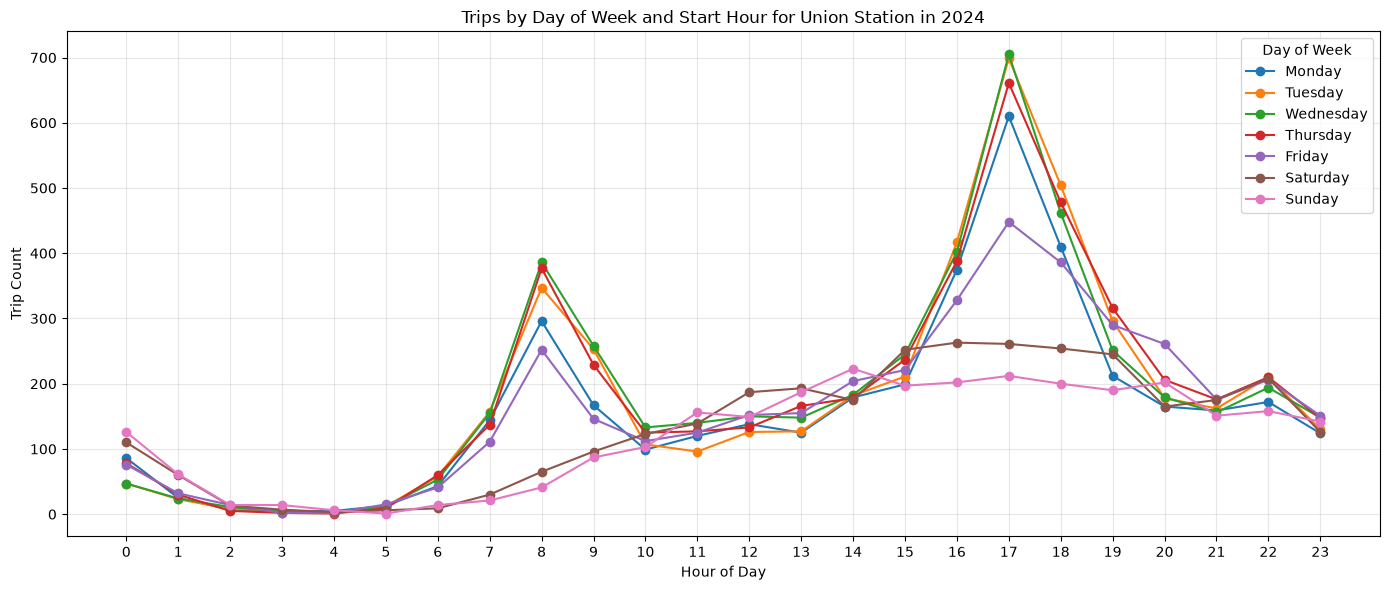

In [22]:
# Code for Figure 1

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]
plt.figure(figsize=(14, 6))
demand = (
    day_hour["2026"]
    .pivot(index="Start_Day_of_Week", columns="Start_Hour", values="Trip_Count")
    .reindex(index=day_order, columns=range(24), fill_value=0)
    .fillna(0)
)
for day in day_order:
    plt.plot(
        demand.columns,
        demand.loc[day],
        marker="o",
        label=day
    )
plt.title("Trips by Day of Week and Start Hour for Union Station in 2024")
plt.xlabel("Hour of Day")
plt.ylabel("Trip Count")
plt.xticks(range(24))
plt.legend(title="Day of Week")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
union_combined = pd.concat([union2024, union2025, union2026], ignore_index=True)

In [24]:
# | label:
# | tbl-cap: Total trips starting at Union Station per date and hour for 2024 and 2025

# Transform data so we get the number of trips per year, month, day, and hour (2024-2025)

transformed_data = union_combined.copy()
start_time = pd.to_datetime(transformed_data["Start_Time"])

transformed_data["date"] = start_time.dt.date
transformed_data["year"] = start_time.dt.year
transformed_data["month"] = start_time.dt.month
transformed_data["day_of_week"] = start_time.dt.day_name()
transformed_data["start_hour"] = start_time.dt.hour

daily_trips = (
    transformed_data.groupby(
        ["date", "year", "month", "day_of_week"],
        as_index=False
    )
    .size()
    .rename(columns={"size": "trip_count"})
)

daily_trips

,date,year,month,day_of_week,trip_count
0,2024-01-01,2024,1,Monday,42
1,2024-01-02,2024,1,Tuesday,63
2,2024-01-03,2024,1,Wednesday,90
3,2024-01-04,2024,1,Thursday,69
4,2024-01-05,2024,1,Friday,50
...,...,...,...,...,...
996,2026-09-26,2026,9,Saturday,128
997,2026-09-27,2026,9,Sunday,124
998,2026-09-28,2026,9,Monday,163
999,2026-09-29,2026,9,Tuesday,195


In [25]:
# | label:
# | tbl-cap: Total trips starting at Union Station per month for 2024-2026
# plot demand per month for the year 2024 and 2025

monthly_trip_counts = (
    daily_trips
    .groupby(["year", "month"], as_index=False)["trip_count"]
    .sum()
    .sort_values(["year", "month"])
    .reset_index(drop=True)
)

monthly_trip_counts


,year,month,trip_count
0,2024,1,1899
1,2024,2,2338
2,2024,3,2333
3,2024,4,2703
4,2024,5,4124
5,2024,6,4856
6,2024,7,5427
7,2024,8,5214
8,2024,9,5532
9,2024,10,5278


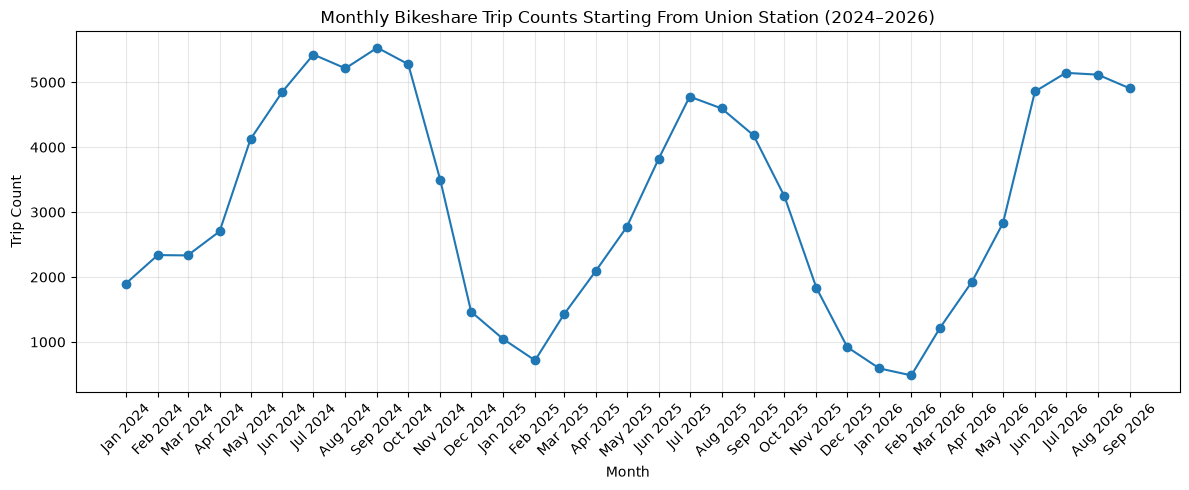

In [26]:
# Time series plot of bike demand throughout 
# 2024-2026 for trips starting from Union Station
# Code for Figure 2

month_chart = monthly_trip_counts.sort_values(["year", "month"]).copy()
month_chart["Date"] = pd.to_datetime(
    dict(year=month_chart["year"], month=month_chart["month"], day=1)
)
plt.figure(figsize=(12, 5))
plt.plot(month_chart["Date"], month_chart["trip_count"], marker="o")
plt.title("Monthly Bikeshare Trip Counts Starting From Union Station (2024–2026)")
plt.xlabel("Month")
plt.ylabel("Trip Count")
plt.xticks(month_chart["Date"], month_chart["Date"].dt.strftime("%b %Y"), rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Create FFT features
df = daily_trips.copy()

df["date"] = pd.to_datetime(df["date"])

df = (
    df.set_index("date")
    .sort_index()
    .asfreq("D")
)

# Fill missing days with zero, if they genuinely had no trips
df["trip_count"] = df["trip_count"].fillna(0)

In [28]:
def fft_features(window):

    # Remove the mean
    x = window - np.mean(window)

    # Compute FFT
    fft_values = np.fft.rfft(x)

    # Compute frequencies (cycles per day)
    frequencies = np.fft.rfftfreq(len(x), d=1)

    # Compute spectral power
    power = np.abs(fft_values) ** 2

    # Exclude zero frequency
    power[0] = 0

    # Find strongest frequency
    dominant_idx = np.argmax(power)

    return frequencies[dominant_idx], power[dominant_idx]

In [29]:
window_size = 28 # Pattern calculated every 28 days

df["dominant_frequency"] = np.nan
df["dominant_power"] = np.nan

for i in range(window_size - 1, len(df)):

    window = df["trip_count"].iloc[
        i - window_size + 1 : i + 1
    ].values

    freq, power = fft_features(window)

    df.iloc[
        i, df.columns.get_loc("dominant_frequency")
    ] = freq

    df.iloc[
        i, df.columns.get_loc("dominant_power")
    ] = power

In [30]:
df.loc[(df["month"] == 1.0) & (df["year"] == 2024)]

,year,month,day_of_week,trip_count,dominant_frequency,dominant_power
date,,,,,,
2024-01-01,2024.0,1.0,Monday,42.0,NaN,NaN
2024-01-02,2024.0,1.0,Tuesday,63.0,NaN,NaN
2024-01-03,2024.0,1.0,Wednesday,90.0,NaN,NaN
2024-01-04,2024.0,1.0,Thursday,69.0,NaN,NaN
2024-01-05,2024.0,1.0,Friday,50.0,NaN,NaN
2024-01-06,2024.0,1.0,Saturday,35.0,NaN,NaN
2024-01-07,2024.0,1.0,Sunday,22.0,NaN,NaN
2024-01-08,2024.0,1.0,Monday,72.0,NaN,NaN
2024-01-09,2024.0,1.0,Tuesday,54.0,NaN,NaN


In [31]:
# Weekday/weekend indicator

df["is_weekend"] = df["day_of_week"].isin(
    ["Saturday", "Sunday"]
).astype(int)

df["trip_count_lag1"] = df["trip_count"]

df

,year,month,day_of_week,trip_count,dominant_frequency,dominant_power,is_weekend,trip_count_lag1
date,,,,,,,,
2024-01-01,2024.0,1.0,Monday,42.0,NaN,NaN,0,42.0
2024-01-02,2024.0,1.0,Tuesday,63.0,NaN,NaN,0,63.0
2024-01-03,2024.0,1.0,Wednesday,90.0,NaN,NaN,0,90.0
2024-01-04,2024.0,1.0,Thursday,69.0,NaN,NaN,0,69.0
2024-01-05,2024.0,1.0,Friday,50.0,NaN,NaN,0,50.0
...,...,...,...,...,...,...,...,...
2026-09-26,2026.0,9.0,Saturday,128.0,0.142857,102565.059987,1,128.0
2026-09-27,2026.0,9.0,Sunday,124.0,0.142857,109043.126355,1,124.0
2026-09-28,2026.0,9.0,Monday,163.0,0.142857,85274.490463,0,163.0


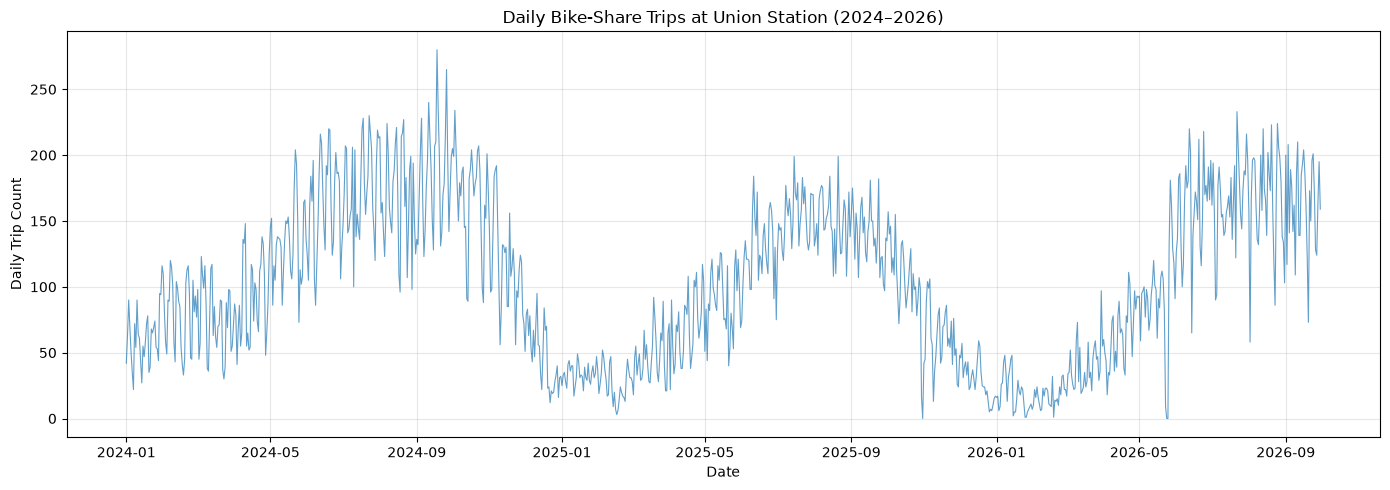

In [32]:
# Daily bikesahre trips 2024-2026

plt.figure(figsize=(14, 5))

plt.plot(
    df.index,
    df["trip_count"],
    linewidth=0.8,
    alpha=0.7
)

plt.title("Daily Bike-Share Trips at Union Station (2024–2026)")
plt.xlabel("Date")
plt.ylabel("Daily Trip Count")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# DWT features: Maximum detail coefficient and maximum approximation coefficient

import numpy as np
import pandas as pd
import pywt

# Sort and check that observations are consecutive calendar days
df = df.sort_index().copy()

if not isinstance(df.index, pd.DatetimeIndex):
    raise ValueError("df needs a DatetimeIndex.")

if df.index.has_duplicates:
    raise ValueError("Resolve duplicate dates before calculating wavelets.")

expected_dates = pd.date_range(
    df.index.min(), df.index.max(), freq="D"
)

if not df.index.equals(expected_dates):
    raise ValueError("Check for missing dates or non-daily observations.")

# Select one complete 16-day window
x = df["trip_count"].iloc[:16].to_numpy(dtype=float)

if len(x) != 16 or not np.isfinite(x).all():
    raise ValueError("This window needs 16 valid daily trip counts.")

# Three-level Haar DWT
cA3, cD3, cD2, cD1 = pywt.wavedec(
    x, "haar", level=3
)

print("Level 3 approximation:", cA3)
print("Level 3 detail:", cD3)
print("Level 2 detail:", cD2)
print("Level 1 detail:", cD1)

Level 3 approximation: [156.62415203 156.27059864]
Level 3 detail: [30.0520382 33.9411255]
Level 2 detail: [-27.   -4.5   9.5 -15.5]
Level 1 detail: [-14.8492424   14.8492424   10.60660172 -35.35533906 -25.45584412
   2.12132034  12.02081528   5.65685425]


In [34]:
max_approx = np.max(cA3)
max_detail = np.max(np.abs(cD3))
detail_idx = np.argmax(np.abs(cD3))

# Midpoint measured in days from the start of the window
detail_time = (detail_idx + 0.5) * 2**3

print("Maximum approximation:", max_approx)
print("Maximum absolute detail:", max_detail)
print("Location of largest detail:", detail_time, "days")

Maximum approximation: 156.6241520328203
Maximum absolute detail: 33.94112549695426
Location of largest detail: 12.0 days


In [35]:
def wavelet_features(x):
    cA3, cD3, cD2, cD1 = pywt.wavedec(
        x, "haar", level=3
    )

    idx = np.argmax(np.abs(cD3))

    return {
        "wavelet_max_approx_3": np.max(cA3),
        "wavelet_max_detail_3": np.max(np.abs(cD3)),
        "wavelet_detail_time_3": (idx + 0.5) * 8,
        "wavelet_signed_detail_3": cD3[idx],
        "wavelet_max_detail_2": np.max(np.abs(cD2)),
        "wavelet_max_detail_1": np.max(np.abs(cD1))
    }


window = 16
feature_rows = []

for i in range(len(df)):
    if i < window - 1:
        feature_rows.append({})
        continue

    x = df["trip_count"].iloc[
        i - window + 1 : i + 1
    ].to_numpy(dtype=float)

    if not np.isfinite(x).all():
        feature_rows.append({})
        continue

    feature_rows.append(wavelet_features(x))

wavelet_df = pd.DataFrame(
    feature_rows,
    index=df.index
)

df = df.join(wavelet_df)

df[["trip_count", *wavelet_df.columns]].tail()

,trip_count,wavelet_max_approx_3,wavelet_max_detail_3,wavelet_detail_time_3,wavelet_signed_detail_3,wavelet_max_detail_2,wavelet_max_detail_1
date,,,,,,,
2026-09-26,128.0,501.338708,63.286057,12.0,-63.286057,63.5,50.204581
2026-09-27,124.0,470.579563,12.020815,12.0,-12.020815,61.0,70.710678
2026-09-28,163.0,462.447835,62.578950,4.0,62.578950,76.0,35.355339
2026-09-29,195.0,470.226009,84.499260,4.0,84.499260,53.0,70.710678
2026-09-30,159.0,473.407990,79.903066,4.0,79.903066,63.5,35.355339


In [36]:
df["target_next_day"] = df["trip_count"].shift(-1)

wavelet_cols = wavelet_df.columns.tolist()

model_data = df.dropna(
    subset=wavelet_cols + ["target_next_day"]
).copy()

In [37]:
df

,year,month,day_of_week,trip_count,dominant_frequency,dominant_power,is_weekend,trip_count_lag1,wavelet_max_approx_3,wavelet_max_detail_3,wavelet_detail_time_3,wavelet_signed_detail_3,wavelet_max_detail_2,wavelet_max_detail_1,target_next_day
date,,,,,,,,,,,,,,,
2024-01-01,2024.0,1.0,Monday,42.0,NaN,NaN,0,42.0,NaN,NaN,NaN,NaN,NaN,NaN,63.0
2024-01-02,2024.0,1.0,Tuesday,63.0,NaN,NaN,0,63.0,NaN,NaN,NaN,NaN,NaN,NaN,90.0
2024-01-03,2024.0,1.0,Wednesday,90.0,NaN,NaN,0,90.0,NaN,NaN,NaN,NaN,NaN,NaN,69.0
2024-01-04,2024.0,1.0,Thursday,69.0,NaN,NaN,0,69.0,NaN,NaN,NaN,NaN,NaN,NaN,50.0
2024-01-05,2024.0,1.0,Friday,50.0,NaN,NaN,0,50.0,NaN,NaN,NaN,NaN,NaN,NaN,35.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-26,2026.0,9.0,Saturday,128.0,0.142857,102565.059987,1,128.0,501.338708,63.286057,12.0,-63.286057,63.5,50.204581,124.0
2026-09-27,2026.0,9.0,Sunday,124.0,0.142857,109043.126355,1,124.0,470.579563,12.020815,12.0,-12.020815,61.0,70.710678,163.0
2026-09-28,2026.0,9.0,Monday,163.0,0.142857,85274.490463,0,163.0,462.447835,62.578950,4.0,62.578950,76.0,35.355339,195.0


In [38]:
df_model = df.dropna(
    subset=["dominant_frequency", "dominant_power"]
).copy()

df_model

,year,month,day_of_week,trip_count,dominant_frequency,dominant_power,is_weekend,trip_count_lag1,wavelet_max_approx_3,wavelet_max_detail_3,wavelet_detail_time_3,wavelet_signed_detail_3,wavelet_max_detail_2,wavelet_max_detail_1,target_next_day
date,,,,,,,,,,,,,,,
2024-01-28,2024.0,1.0,Sunday,44.0,0.142857,64887.890311,1,44.0,164.755880,24.748737,4.0,-24.748737,15.5,30.405592,95.0
2024-01-29,2024.0,1.0,Monday,95.0,0.142857,55644.599864,0,95.0,184.554870,13.081475,4.0,-13.081475,38.0,36.062446,94.0
2024-01-30,2024.0,1.0,Tuesday,94.0,0.142857,65308.544329,0,94.0,193.747258,8.485281,12.0,-8.485281,46.0,30.405592,116.0
2024-01-31,2024.0,1.0,Wednesday,116.0,0.142857,79248.062332,0,116.0,211.778481,35.001786,12.0,-35.001786,35.5,36.062446,110.0
2024-02-01,2024.0,2.0,Thursday,110.0,0.142857,94287.257967,0,110.0,226.274170,67.175144,12.0,-67.175144,18.5,30.405592,81.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-26,2026.0,9.0,Saturday,128.0,0.142857,102565.059987,1,128.0,501.338708,63.286057,12.0,-63.286057,63.5,50.204581,124.0
2026-09-27,2026.0,9.0,Sunday,124.0,0.142857,109043.126355,1,124.0,470.579563,12.020815,12.0,-12.020815,61.0,70.710678,163.0
2026-09-28,2026.0,9.0,Monday,163.0,0.142857,85274.490463,0,163.0,462.447835,62.578950,4.0,62.578950,76.0,35.355339,195.0


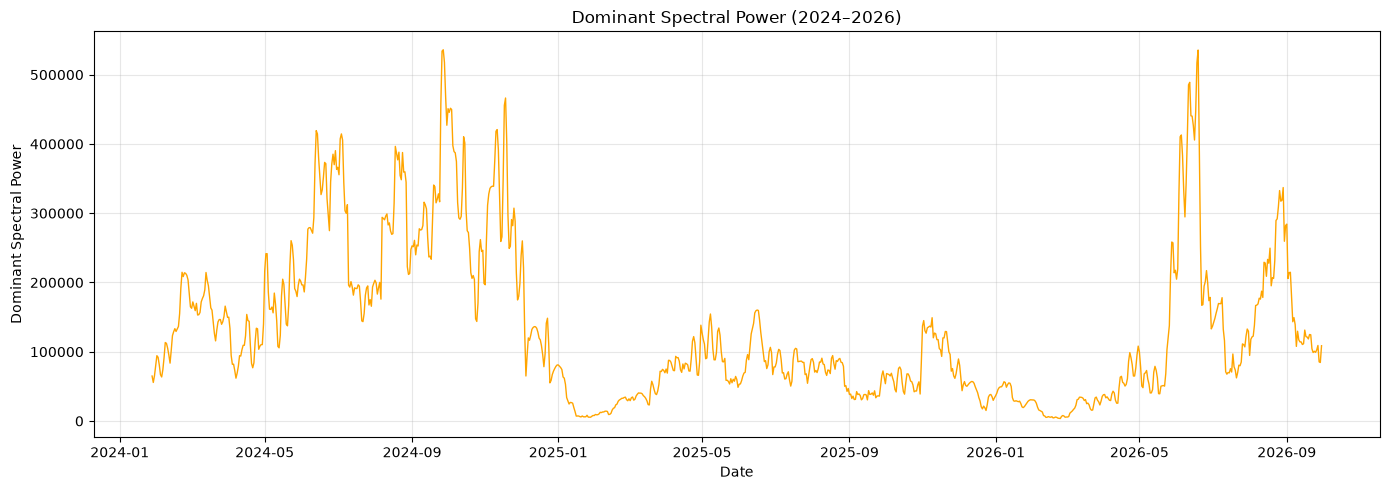

In [39]:
plt.figure(figsize=(14, 5))

plt.plot(
    df.index,
    df["dominant_power"],
    linewidth=1,
    color="orange"
)

plt.title("Dominant Spectral Power (2024–2026)")
plt.xlabel("Date")
plt.ylabel("Dominant Spectral Power")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

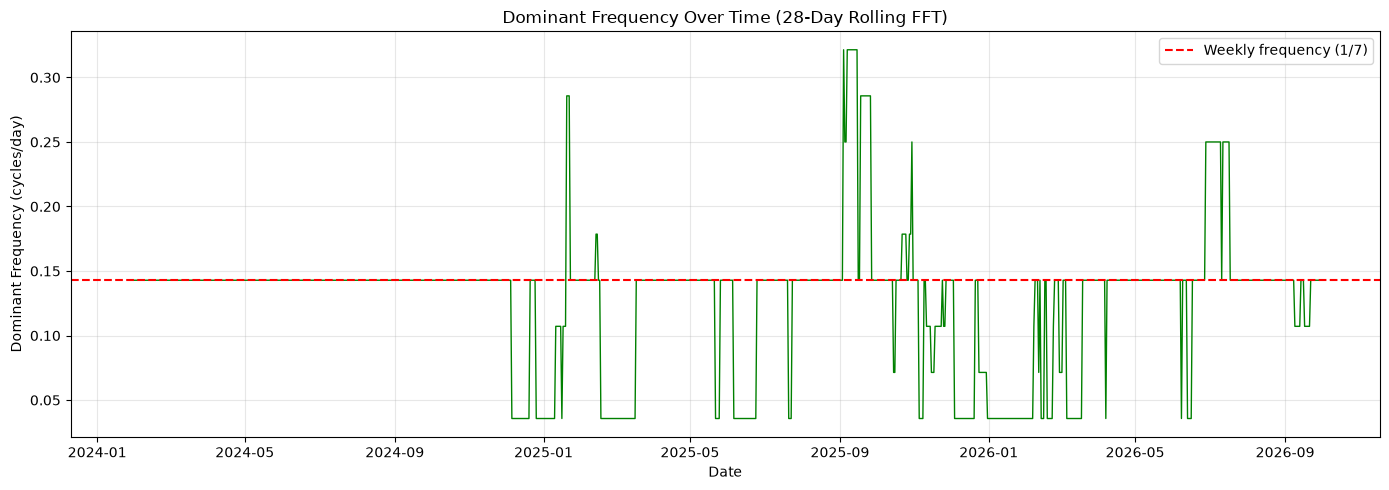

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    df.index,
    df["dominant_frequency"],
    linewidth=1,
    color="green"
)

plt.axhline(
    y=1/7,
    color="red",
    linestyle="--",
    label="Weekly frequency (1/7)"
)

plt.title("Dominant Frequency Over Time (28-Day Rolling FFT)")
plt.xlabel("Date")
plt.ylabel("Dominant Frequency (cycles/day)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
#Next steps
#initialize a random forest
#do time series cross-validation for tree tuning
#calculate errors and predictor importance
#interpret the results

In [ ]:
df_model = df.sort_index().copy()

# Target: tomorrow's trip count
df_model["target_next_day"] = df_model["trip_count"].shift(-1)

# Previous day's trip count relative to the prediction date
df_model["trip_count_lag1"] = df_model["trip_count"]

# Calendar information for the day being predicted
next_date = df_model.index + pd.Timedelta(days=1)

df_model["year"] = next_date.year
df_model["month"] = next_date.month
df_model["day_of_week"] = next_date.dayofweek
df_model["is_weekend"] = (next_date.dayofweek >= 5).astype(int)

# Select predictors
features = [
    # "year",
    "month",
    "day_of_week",
    "dominant_frequency",
    "dominant_power",
    "wavelet_max_approx_3",
    "wavelet_max_detail_3",	
    # "wavelet_detail_time_3"
    # "wavelet_signed_detail_3",
    "wavelet_max_detail_2",
    "wavelet_max_detail_1",	
    "is_weekend",
    "trip_count_lag1"
]

# Remove rows with missing predictors or target
df_model = df_model.dropna(
    subset=features + ["target_next_day"]
)

In [69]:
target_dates = df_model.index + pd.Timedelta(days=1)

train = df_model.loc[target_dates < "2025-07-01"].copy()

val = df_model.loc[
    (target_dates >= "2025-07-01") &
    (target_dates < "2026-01-01")
].copy()

test = df_model.loc[
    target_dates >= "2026-01-01"
].copy()

X_train = train[features]
y_train = train["target_next_day"]

X_val = val[features]
y_val = val["target_next_day"]

X_test = test[features]
y_test = test["target_next_day"]

In [70]:
for name, data in [
    ("Training", train),
    ("Validation", val),
    ("Testing", test)
]:
    print(
        name,
        len(data),
        data.index.min(),
        data.index.max()
    )

Training 519 2024-01-28 00:00:00 2025-06-29 00:00:00
Validation 184 2025-06-30 00:00:00 2025-12-30 00:00:00
Testing 273 2025-12-31 00:00:00 2026-09-29 00:00:00


In [71]:
# | label: tbl-tree-depth
# | tbl-cap: "Training and Cross-Validation RMSE by Tree Depth"

import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error
from IPython.display import Markdown, display

# Finding optimal tree depth
depths = [1,2,3,4,5,6,7,8,9,10,11]
depth_results = []

# 5-fold time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5, gap=1)

for depth in depths:

    tree = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    # Fit model on training data
    tree.fit(X_train, y_train)

    # Predictions on training data
    train_predictions = tree.predict(X_train)

    # Calculate training RMSE
    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_predictions)
    )

    # Calculate cross-validation RMSE
    cv_scores = cross_val_score(
        tree,
        X_train,
        y_train,
        cv=tscv,
        scoring="neg_root_mean_squared_error"
    )

    cv_rmse = -cv_scores.mean()

    depth_results.append({
        "Max Depth": depth,
        "Training RMSE": train_rmse,
        "CV RMSE": cv_rmse
    })

depth_results_df = pd.DataFrame(depth_results)

display(Markdown(depth_results_df.to_markdown(index=False)))

|   Max Depth |   Training RMSE |   CV RMSE |
|------------:|----------------:|----------:|
|           1 |        37.5472  |   50.3866 |
|           2 |        30.2103  |   44.6601 |
|           3 |        25.2516  |   35.8954 |
|           4 |        22.1319  |   36.911  |
|           5 |        19.2287  |   36.9144 |
|           6 |        16.2704  |   39.6516 |
|           7 |        13.7413  |   40.4309 |
|           8 |        11.0151  |   40.5059 |
|           9 |         8.38144 |   40.6743 |
|          10 |         6.38392 |   40.9757 |
|          11 |         4.97144 |   40.8497 |

In [46]:
# | label: tbl-rf-tree-tuning
# | tbl-cap: "Random Forest RMSE by Number of Trees"

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error
from IPython.display import Markdown, display

# Training data must be sorted chronologically
train = train.sort_index()
X_train = train[features]
y_train = train["target_next_day"]

# Tuning number of trees
n_trees = [10, 50, 100, 200, 500, 1000, 1500]
tree_results = []

# 5-fold time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5, gap=1)

for n in n_trees:

    model = RandomForestRegressor(
        n_estimators=n,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )

    # Fit on the full training set and calculate training RMSE
    model.fit(X_train, y_train)
    train_predictions = model.predict(X_train)

    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_predictions)
    )

    # Refit and evaluate on each chronological CV fold
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=tscv,
        scoring="neg_root_mean_squared_error"
    )

    tree_results.append({
        "Number of Trees": n,
        "Training RMSE": train_rmse,
        "CV RMSE": -cv_scores.mean()
        # "CV RMSE SD": cv_scores.std()
    })

tree_results_df = pd.DataFrame(tree_results)

display(Markdown(
    tree_results_df.to_markdown(index=False, floatfmt=".2f")
))

|   Number of Trees |   Training RMSE |   CV RMSE |
|------------------:|----------------:|----------:|
|             10.00 |           10.61 |     37.60 |
|             50.00 |            8.71 |     37.50 |
|            100.00 |            8.49 |     37.60 |
|            200.00 |            8.36 |     37.27 |
|            500.00 |            8.48 |     37.10 |
|           1000.00 |            8.44 |     37.11 |
|           1500.00 |            8.44 |     37.21 |

In [47]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Use the same predictors for training and testing
X_train = train[features]
y_train = train["target_next_day"]

X_test = test[features]
y_test = test["target_next_day"]

# Fit the final model on training data only
rf = RandomForestRegressor(
    n_estimators=500,
    max_depth=3,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# Predict the held-out testing data
test_predictions = rf.predict(X_test)

# Testing performance
test_results = pd.DataFrame([{
    "Model": "Random Forest",
    "Number of Trees": 500,
    "Max Depth": 3,
    "Test RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
    "Test MAE": mean_absolute_error(y_test, test_predictions)
}])

display(test_results)

,Model,Number of Trees,Max Depth,Test RMSE,Test MAE
0,Random Forest,500,3,28.264497,22.065843


In [48]:
# | label: tbl-rf-permutation-importance
# | tbl-cap: "Random Forest Permutation Predictor Importance"

from sklearn.inspection import permutation_importance
from IPython.display import Markdown, display
import pandas as pd

# Permutation importance on held-out testing data
perm = permutation_importance(
    rf,
    X_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

# Summarize and rank predictors
importance_df = pd.DataFrame({
    "Predictor": X_test.columns,
    "Mean Increase in RMSE": perm.importances_mean
}).sort_values(
    "Mean Increase in RMSE",
    ascending=False
).reset_index(drop=True)

display(Markdown(
    importance_df.to_markdown(index=False, floatfmt=".3f")
))

| Predictor            |   Mean Increase in RMSE |
|:---------------------|------------------------:|
| wavelet_max_approx_3 |                  17.060 |
| trip_count_lag1      |                  13.571 |
| month                |                   3.134 |
| dominant_power       |                   2.293 |
| wavelet_max_detail_2 |                   1.322 |
| wavelet_max_detail_1 |                   1.264 |
| day_of_week          |                   1.152 |
| is_weekend           |                   0.843 |
| wavelet_max_detail_3 |                   0.196 |
| dominant_frequency   |                   0.046 |
| year                 |                  -0.000 |

In [ ]:
# LASSO regression model

from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# assign each predictor as either categorical or numeric
categorical = ["month", "day_of_week"]
numeric = [
    f for f in features
    if f not in categorical + ["is_weekend"] # not including is_weekend since it's explained by day categories
]
# for categorical predictors, drop the first category to prevent multicollinearity
preprocessor = ColumnTransformer([
    ("calendar", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ), categorical),
    ("numeric", StandardScaler(), numeric) #standardize numeric ones
])

lasso = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=10000))
])

In [55]:
X_train = train[features]
y_train = train["target_next_day"]

lasso.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['year','month','day_of_week',...,'wavelet_max_detail_1','is_weekend', 'trip_count_lag1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('calendar', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thro

In [77]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
import pandas as pd

train = train.sort_index()
X_train = train[features]
y_train = train["target_next_day"]

tscv = TimeSeriesSplit(n_splits=5, gap=1)

search = GridSearchCV(
    estimator=lasso,
    param_grid={"model__alpha": [0.001, 0.01, 0.1, 0.5, 1, 5, 10, 50, 100]},
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    return_train_score=True,
    n_jobs=-1
)

search.fit(X_train, y_train)

results = pd.DataFrame(search.cv_results_)

lasso_results = pd.DataFrame({
    "Alpha": results["param_model__alpha"].astype(float),
    "Training RMSE": -results["mean_train_score"],
    "CV RMSE": -results["mean_test_score"]
}).sort_values("Alpha")

display(lasso_results)

best_lasso = search.best_estimator_
print("Best alpha:", search.best_params_["model__alpha"])

,Alpha,Training RMSE,CV RMSE
0,0.001,20.793750,43.299774
1,0.010,20.798799,43.689972
2,0.100,20.951092,40.094963
3,0.500,21.958960,33.623044
4,1.000,23.006296,31.418820
5,5.000,29.537748,34.014192
6,10.000,30.872430,39.001504
7,50.000,49.303197,69.234155
8,100.000,50.159693,69.621806


Best alpha: 1


In [78]:
best_lasso

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['year','month','day_of_week',...,'wavelet_max_detail_1','is_weekend', 'trip_count_lag1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('calendar', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thro

In [79]:
predictor_names = (
    best_lasso.named_steps["preprocessor"].get_feature_names_out()
)

coefficients = pd.DataFrame({
    "Predictor": predictor_names,
    "Coefficient": best_lasso.named_steps["model"].coef_
})

coefficients["Absolute Coefficient"] = coefficients["Coefficient"].abs()

display(
    coefficients.sort_values("Absolute Coefficient", ascending=False)
)

,Predictor,Coefficient,Absolute Coefficient
20,numeric__wavelet_max_approx_3,26.061412,26.061412
24,numeric__trip_count_lag1,26.049167,26.049167
15,calendar__day_of_week_5,-25.866567,25.866567
16,calendar__day_of_week_6,-14.502565,14.502565
14,calendar__day_of_week_4,-13.269386,13.269386
11,calendar__day_of_week_1,2.317622,2.317622
22,numeric__wavelet_max_detail_2,0.992196,0.992196
21,numeric__wavelet_max_detail_3,0.459294,0.459294
0,calendar__month_2,-0.000000,0.000000
8,calendar__month_10,-0.000000,0.000000


In [80]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

X_test = test[features]
y_test = test["target_next_day"]

predictions = best_lasso.predict(X_test)

print("Test RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("Test MAE:", mean_absolute_error(y_test, predictions))

Test RMSE: 25.612837339071373
Test MAE: 17.973709995377718
